# Step 3 - Churn Definition and Feature Engineering (no data leakage)
**Objective 2 (data side):** build the table that the churn models will learn from.

**The idea.** Pick a *cut-off date*. Describe every customer using **only what happened before that date** (the features). Then look at the next 150 days and record whether they came back (the label).

```
 history  (features come only from here)          outcome window (label comes only from here)
 |----------------------------------------------|-----------------------------------------|
 start of data                              CUT-OFF DATE                         cut-off + 150 days
```

A customer is **churned (1)** if they made **no purchase** in the 150 days after the cut-off, and **retained (0)** if they bought at least once.

**Why 150 days?** Step 2 showed that 90% of the gaps between a customer's purchases are shorter than 148 days, so being silent for 150 days means a customer has clearly broken their normal rhythm.

**Why several cut-off dates?** Revenue is highly seasonal and one date could give a lucky or unlucky result. We build several *snapshots*, train on the earlier ones and test on the latest one. The training outcome windows must finish **before** the test cut-off, otherwise training labels would peek into the test period. The notebook checks this automatically.

**Output:** `data/churn_dataset.csv` (one row per customer per snapshot), plus `data/feature_dictionary.csv`.

## 1. Setup and load

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 60
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DATA, FIG = "data", "figures"
os.makedirs(FIG, exist_ok=True)

sales = pd.read_csv(f"{DATA}/clean_sales.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str})
returns = pd.read_csv(f"{DATA}/clean_returns.csv", parse_dates=["InvoiceDate"], dtype={"StockCode": str})

# Same fix as in Step 2: remove very large order lines that were later cancelled in full
big = sales[sales["Revenue"] >= 20000].reset_index()
pairs = big.merge(returns.reset_index()[["index", "CustomerID", "StockCode", "ReturnQty", "InvoiceDate"]],
                  left_on=["CustomerID", "StockCode", "Quantity"], right_on=["CustomerID", "StockCode", "ReturnQty"],
                  suffixes=("", "_ret"))
pairs = pairs[pairs["InvoiceDate_ret"] >= pairs["InvoiceDate"]]
sales = sales.drop(index=pairs["index"].unique())
returns = returns.drop(index=pairs["index_ret"].unique())
print(f"Removed {len(pairs)} fully-cancelled mega order line(s)")

sales = sales.sort_values("InvoiceDate").reset_index(drop=True)
returns = returns.sort_values("InvoiceDate").reset_index(drop=True)
DATA_START, DATA_END = sales["InvoiceDate"].min(), sales["InvoiceDate"].max()
print(f"sales: {len(sales):,} rows | returns: {len(returns):,} rows")
print(f"Data runs from {DATA_START:%d %b %Y} to {DATA_END:%d %b %Y}")

Removed 3 fully-cancelled mega order line(s)
sales: 776,572 rows | returns: 17,583 rows
Data runs from 01 Dec 2009 to 09 Dec 2011


## 2. Design choices (the only settings you may want to change)

| Setting | Value | Meaning |
|---|---|---|
| `CHURN_DAYS` | 150 | No purchase for this many days after the cut-off = churned |
| `ACTIVE_DAYS` | 365 | Only customers who bought in the year before the cut-off are included. Without this, customers who left long ago would be trivially "churned" and make the problem look easier than it is |
| `TEST_CUTOFF` | 1 Jul 2011 | Latest snapshot, used only for the final test. Its 150-day window ends 28 Nov 2011, inside the data |
| `CANDIDATE_CUTOFFS` | every 2 months | Training snapshots. Any whose outcome window would reach past the test cut-off are dropped automatically |

Train cut-offs: ['2010-06-30', '2010-08-31', '2010-10-31', '2010-12-31']
Test cut-off  : 2011-07-01
Dropped (outcome window would overlap the test period): ['2011-02-28']


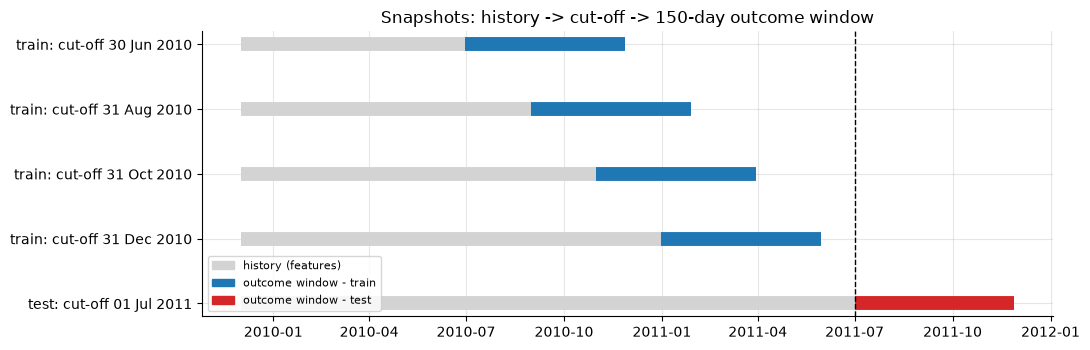

In [2]:
CHURN_DAYS = 150
ACTIVE_DAYS = 365
TEST_CUTOFF = pd.Timestamp("2011-07-01")
CANDIDATE_CUTOFFS = ["2010-06-30", "2010-08-31", "2010-10-31", "2010-12-31", "2011-02-28"]

delta = pd.Timedelta(days=CHURN_DAYS)
TRAIN_CUTOFFS = [pd.Timestamp(c) for c in CANDIDATE_CUTOFFS if pd.Timestamp(c) + delta <= TEST_CUTOFF]
dropped = [c for c in CANDIDATE_CUTOFFS if pd.Timestamp(c) + delta > TEST_CUTOFF]

assert TEST_CUTOFF + delta <= DATA_END.normalize() + pd.Timedelta(days=1), "test outcome window runs past the end of the data"
assert all(c + delta <= TEST_CUTOFF for c in TRAIN_CUTOFFS), "a training window overlaps the test period"
print("Train cut-offs:", [f"{c:%Y-%m-%d}" for c in TRAIN_CUTOFFS])
print("Test cut-off  :", f"{TEST_CUTOFF:%Y-%m-%d}")
if dropped:
    print("Dropped (outcome window would overlap the test period):", dropped)

rows = [(c, "train") for c in TRAIN_CUTOFFS] + [(TEST_CUTOFF, "test")]
fig, ax = plt.subplots(figsize=(11, 3.6))
for i, (c, role) in enumerate(rows):
    ax.hlines(i, DATA_START.to_pydatetime(), c.to_pydatetime(), color="lightgrey", lw=10)
    ax.hlines(i, c.to_pydatetime(), (c + delta).to_pydatetime(),
              color="tab:blue" if role == "train" else "tab:red", lw=10)
ax.set_yticks(range(len(rows)))
ax.set_yticklabels([f"{role}: cut-off {c:%d %b %Y}" for c, role in rows])
ax.invert_yaxis()
ax.axvline(TEST_CUTOFF.to_pydatetime(), ls="--", c="k", lw=1)
ax.legend(handles=[Patch(color="lightgrey", label="history (features)"),
                   Patch(color="tab:blue", label="outcome window - train"),
                   Patch(color="tab:red", label="outcome window - test")], loc="lower left", fontsize=8)
ax.set_title("Snapshots: history -> cut-off -> 150-day outcome window")
plt.tight_layout(); plt.savefig(f"{FIG}/12_snapshot_timeline.png", dpi=120); plt.show()

## 3. The feature builder
`build_snapshot(cutoff, sales, returns)` is the heart of this notebook.

- **History** = rows with `InvoiceDate < cutoff`. Features use only this.
- **Outcome window** = rows with `cutoff <= InvoiceDate < cutoff + 150 days`. Only the label (and the `Outcome_` columns) use this.
- **Population** = customers who bought in the `ACTIVE_DAYS` before the cut-off.

| Feature | Meaning |
|---|---|
| `Recency` | days since the last purchase |
| `Frequency` | number of orders so far |
| `Monetary`, `AvgOrderValue` | total spend and average order value |
| `AvgGapDays`, `StdGapDays` | average and spread of days between purchases (empty for customers with too few orders) |
| `RecencyGapRatio` | `Recency / AvgGapDays`: above 1 means the customer is "overdue" compared with their own rhythm |
| `Orders90`, `Spend90` | orders and spend in the last 90 days |
| `OrdersTrend`, `SpendTrend` | last 90 days compared with the 90 days before, from -1 (collapse) to +1 (surge) |
| `DistinctProducts` | different products ever bought |
| `AvgItemsPerOrder`, `AvgLinesPerOrder` | basket size |
| `ReturnRate`, `ReturnCount` | share of spend that was returned, and number of returns |
| `Tenure` | days since the first purchase |
| `PurchaseRate` | orders per 30 days of tenure |
| `Country`, `IsUK` | where the customer is based |

In [3]:
def build_snapshot(cutoff, sales, returns):
    """One row per active customer at `cutoff`. Features use ONLY data before the cut-off."""
    cutoff = pd.Timestamp(cutoff)
    end = cutoff + pd.Timedelta(days=CHURN_DAYS)

    # ---------- history: strictly before the cut-off ----------
    hist = sales[sales["InvoiceDate"] < cutoff]
    last_seen = hist.groupby("CustomerID")["InvoiceDate"].max()
    active = last_seen[last_seen >= cutoff - pd.Timedelta(days=ACTIVE_DAYS)].index
    h = hist[hist["CustomerID"].isin(active)]

    orders = (h.groupby(["CustomerID", "Invoice"])
                .agg(Date=("InvoiceDate", "min"), Value=("Revenue", "sum"),
                     Items=("Quantity", "sum"), Lines=("StockCode", "nunique"))
                .reset_index())

    o = orders.groupby("CustomerID").agg(
        Frequency=("Invoice", "count"), Monetary=("Value", "sum"), AvgOrderValue=("Value", "mean"),
        AvgItemsPerOrder=("Items", "mean"), AvgLinesPerOrder=("Lines", "mean"),
        First=("Date", "min"), Last=("Date", "max"))
    p = h.groupby("CustomerID").agg(DistinctProducts=("StockCode", "nunique"), Country=("Country", "last"))

    # days between consecutive purchase days
    days = (orders.assign(Day=orders["Date"].dt.normalize())
                  .drop_duplicates(["CustomerID", "Day"]).sort_values(["CustomerID", "Day"]))
    days["Gap"] = days.groupby("CustomerID")["Day"].diff().dt.days
    gap = days.groupby("CustomerID")["Gap"].agg(AvgGapDays="mean", StdGapDays="std")

    # last 90 days vs the 90 days before that
    d90, d180 = cutoff - pd.Timedelta(days=90), cutoff - pd.Timedelta(days=180)
    recent = (orders[orders["Date"] >= d90].groupby("CustomerID")
              .agg(Orders90=("Invoice", "count"), Spend90=("Value", "sum")))
    prev = (orders[(orders["Date"] >= d180) & (orders["Date"] < d90)].groupby("CustomerID")
            .agg(OrdersPrev90=("Invoice", "count"), SpendPrev90=("Value", "sum")))

    # returns before the cut-off
    r = returns[returns["InvoiceDate"] < cutoff].groupby("CustomerID").agg(
        ReturnValue=("ReturnValue", "sum"), ReturnCount=("Invoice", "nunique"))

    f = o.join([p, gap, recent, prev, r])
    for c in ["Orders90", "Spend90", "OrdersPrev90", "SpendPrev90", "ReturnValue", "ReturnCount"]:
        f[c] = f[c].fillna(0)

    f["Recency"] = (cutoff - f["Last"].dt.normalize()).dt.days
    f["Tenure"] = (cutoff - f["First"].dt.normalize()).dt.days
    f["PurchaseRate"] = f["Frequency"] / np.maximum(f["Tenure"], 30) * 30
    f["RecencyGapRatio"] = np.where(f["AvgGapDays"] > 0, f["Recency"] / f["AvgGapDays"], np.nan)

    def trend(new, old):
        tot = new + old
        return np.where(tot > 0, (new - old) / tot.where(tot > 0, 1), 0.0)
    f["OrdersTrend"] = trend(f["Orders90"], f["OrdersPrev90"])
    f["SpendTrend"] = trend(f["Spend90"], f["SpendPrev90"])
    f["ReturnRate"] = (f["ReturnValue"] / f["Monetary"]).clip(0, 1)
    f["IsUK"] = (f["Country"] == "United Kingdom").astype(int)

    # ---------- outcome: from the cut-off onwards (used for the label only) ----------
    fut = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < end)]
    fo = fut.groupby("CustomerID").agg(Outcome_FutureOrders=("Invoice", "nunique"), Outcome_FutureSpend=("Revenue", "sum"))
    f = f.join(fo)
    f["Outcome_FutureOrders"] = f["Outcome_FutureOrders"].fillna(0)
    f["Outcome_FutureSpend"] = f["Outcome_FutureSpend"].fillna(0)
    f["Churn"] = (f["Outcome_FutureOrders"] == 0).astype(int)

    f["SnapshotDate"] = cutoff
    f["WindowEnd"] = end
    return f.drop(columns=["First", "Last", "OrdersPrev90", "SpendPrev90", "ReturnValue"]).reset_index()


FEATURES = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "AvgGapDays", "StdGapDays", "RecencyGapRatio",
            "Orders90", "Spend90", "OrdersTrend", "SpendTrend", "DistinctProducts", "AvgItemsPerOrder",
            "AvgLinesPerOrder", "ReturnRate", "ReturnCount", "Tenure", "PurchaseRate", "Country", "IsUK"]
print("build_snapshot defined with", len(FEATURES), "features")

build_snapshot defined with 20 features


## 4. Build all snapshots and stack them

In [4]:
parts = []
for c in TRAIN_CUTOFFS + [TEST_CUTOFF]:
    s = build_snapshot(c, sales, returns)
    s["Split"] = "test" if c == TEST_CUTOFF else "train"
    parts.append(s)

churn = pd.concat(parts, ignore_index=True)
churn = churn[["CustomerID", "SnapshotDate", "WindowEnd", "Split"] + FEATURES
              + ["Churn", "Outcome_FutureOrders", "Outcome_FutureSpend"]]

summary = (churn.groupby(["SnapshotDate", "Split"])
                .agg(Customers=("CustomerID", "size"), Churned=("Churn", "sum"), ChurnRate=("Churn", "mean"))
                .reset_index())
summary["SnapshotDate"] = summary["SnapshotDate"].dt.strftime("%Y-%m-%d")
display(summary)
print(f"Total rows: {len(churn):,} | train: {(churn['Split'] == 'train').sum():,} | test: {(churn['Split'] == 'test').sum():,}")
print(f"Overall churn rate: {churn['Churn'].mean():.1%}")

,SnapshotDate,Split,Customers,Churned,ChurnRate
0,2010-06-30,train,2939,953,0.32
1,2010-08-31,train,3291,1211,0.37
2,2010-10-31,train,3903,1862,0.48
3,2010-12-31,train,4205,2363,0.56
4,2011-07-01,test,4313,1969,0.46


Total rows: 18,651 | train: 14,338 | test: 4,313
Overall churn rate: 44.8%


## 5. Leakage tests
Every line should say `PASS`. These are what protect the project from the most common churn-modelling mistake.

1. **Time order:** every feature comes from purchases made at least 1 day before the cut-off.
2. **Truncation test:** deleting *all* data after the cut-off and rebuilding the features gives exactly the same features. If any feature used future information, it would change.
3. **Independent label check:** the label is recomputed a second, different way and must match.
4. **Train/test separation:** every training outcome window ends before the test cut-off.
5. **No future customers:** nobody is in a snapshot before their first purchase.

In [5]:
results = []

def check(name, ok):
    results.append(bool(ok))
    print(("PASS  " if ok else "FAIL  ") + name)

# 1. recency is at least 1 day everywhere, so the last purchase is before the cut-off
check("1. Recency >= 1 day for every row (all purchases are before the cut-off)", churn["Recency"].min() >= 1)

# 2. truncation test on every snapshot
ok2 = True
for c in TRAIN_CUTOFFS + [TEST_CUTOFF]:
    full = build_snapshot(c, sales, returns).set_index("CustomerID")[FEATURES]
    cut = build_snapshot(c, sales[sales["InvoiceDate"] < c], returns[returns["InvoiceDate"] < c]).set_index("CustomerID")[FEATURES]
    try:
        pd.testing.assert_frame_equal(full.sort_index(), cut.sort_index(), check_exact=False)
    except AssertionError:
        ok2 = False
check("2. Features are identical when all post-cut-off data is deleted", ok2)

# 3. independent label check: first purchase on/after the cut-off, compared with the window end
ok3 = True
for c in TRAIN_CUTOFFS + [TEST_CUTOFF]:
    snap = churn[churn["SnapshotDate"] == c].set_index("CustomerID")
    nxt = sales[sales["InvoiceDate"] >= c].groupby("CustomerID")["InvoiceDate"].min()
    nxt = nxt.reindex(snap.index)
    expected = (nxt.isna() | (nxt >= c + delta)).astype(int)
    ok3 &= bool((expected == snap["Churn"]).all())
check("3. Churn label matches an independent recomputation", ok3)

# 4. train windows end before the test cut-off
train_end = churn.loc[churn["Split"] == "train", "WindowEnd"].max()
check(f"4. Latest training window ends {train_end:%d %b %Y}, on/before test cut-off {TEST_CUTOFF:%d %b %Y}", train_end <= TEST_CUTOFF)

# 5. tenure >= 1 means the first purchase is before the cut-off
check("5. Tenure >= 1 day for every row (no customer appears before their first purchase)", churn["Tenure"].min() >= 1)

check("6. No duplicate customer within a snapshot", not churn.duplicated(["CustomerID", "SnapshotDate"]).any())
check("7. Churn is strictly 0/1 and has no missing values", set(churn["Churn"].unique()) <= {0, 1} and churn["Churn"].notna().all())
print()
print("ALL TESTS PASSED" if all(results) else "SOME TESTS FAILED - do not continue until fixed")

PASS  1. Recency >= 1 day for every row (all purchases are before the cut-off)
PASS  2. Features are identical when all post-cut-off data is deleted
PASS  3. Churn label matches an independent recomputation
PASS  4. Latest training window ends 30 May 2011, on/before test cut-off 01 Jul 2011
PASS  5. Tenure >= 1 day for every row (no customer appears before their first purchase)
PASS  6. No duplicate customer within a snapshot
PASS  7. Churn is strictly 0/1 and has no missing values

ALL TESTS PASSED


## 6. Sanity checks on the table
Before modelling, make sure the table looks sensible: how much is missing, whether the features separate churners from non-churners, and whether any features are near-duplicates of each other.

In [6]:
miss = churn[FEATURES].isna().mean().mul(100).rename("missing_%")
display(miss[miss > 0].to_frame())
print("AvgGapDays / StdGapDays / RecencyGapRatio are empty for customers with too few orders - this is expected.")
print("Step 4 must fill them (for example with the median, plus a 'single order' flag) INSIDE the training pipeline.")
print()
display(churn[FEATURES].describe().T[["mean", "min", "50%", "max"]])

,missing_%
AvgGapDays,35.42
StdGapDays,55.21
RecencyGapRatio,35.42


AvgGapDays / StdGapDays / RecencyGapRatio are empty for customers with too few orders - this is expected.
Step 4 must fill them (for example with the median, plus a 'single order' flag) INSIDE the training pipeline.



,mean,min,50%,max
Recency,98.68,1.00,67.00,365.00
Frequency,4.38,1.00,2.00,251.00
Monetary,"1,994.56",1.30,679.02,"427,931.29"
AvgOrderValue,372.48,1.30,286.71,"14,844.77"
AvgGapDays,76.69,1.00,58.73,540.00
StdGapDays,39.73,0.00,28.58,354.97
RecencyGapRatio,2.45,0.00,0.78,338.00
Orders90,1.24,0.00,1.00,80.00
Spend90,552.27,0.00,169.00,"111,637.44"
OrdersTrend,0.08,-1.00,0.00,1.00


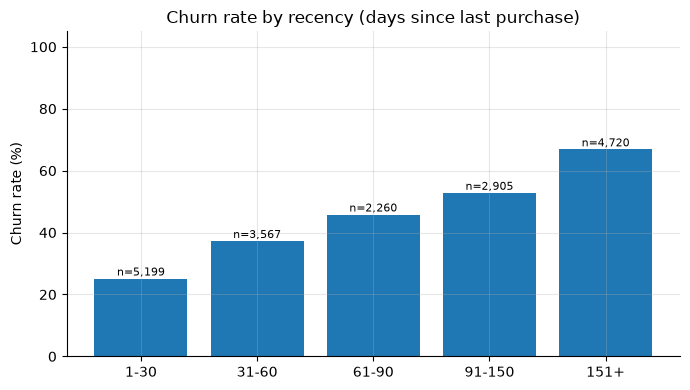

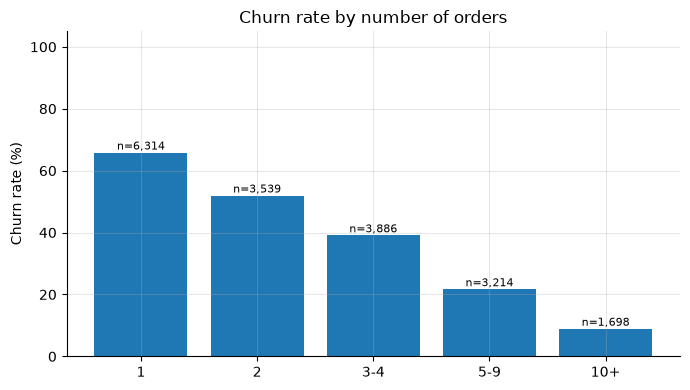

Churn rate: UK customers 45.0% vs non-UK 42.0%


In [7]:
def bucket_chart(col, bins, labels, title, fname):
    b = pd.cut(churn[col], bins=bins, labels=labels)
    t = churn.groupby(b, observed=True)["Churn"].agg(["mean", "size"])
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(t.index.astype(str), t["mean"] * 100)
    for i, (m, n) in enumerate(zip(t["mean"], t["size"])):
        ax.text(i, m * 100 + 1, f"n={n:,}", ha="center", fontsize=8)
    ax.set_ylabel("Churn rate (%)"); ax.set_title(title); ax.set_ylim(0, 105)
    plt.tight_layout(); plt.savefig(f"{FIG}/{fname}.png", dpi=120); plt.show()
    return t

r_tab = bucket_chart("Recency", [0, 30, 60, 90, 150, 400], ["1-30", "31-60", "61-90", "91-150", "151+"],
                     "Churn rate by recency (days since last purchase)", "13_churn_by_recency")
f_tab = bucket_chart("Frequency", [0, 1, 2, 4, 9, 10000], ["1", "2", "3-4", "5-9", "10+"],
                     "Churn rate by number of orders", "14_churn_by_frequency")

uk = churn.groupby("IsUK")["Churn"].mean()
print(f"Churn rate: UK customers {uk[1]:.1%} vs non-UK {uk[0]:.1%}")

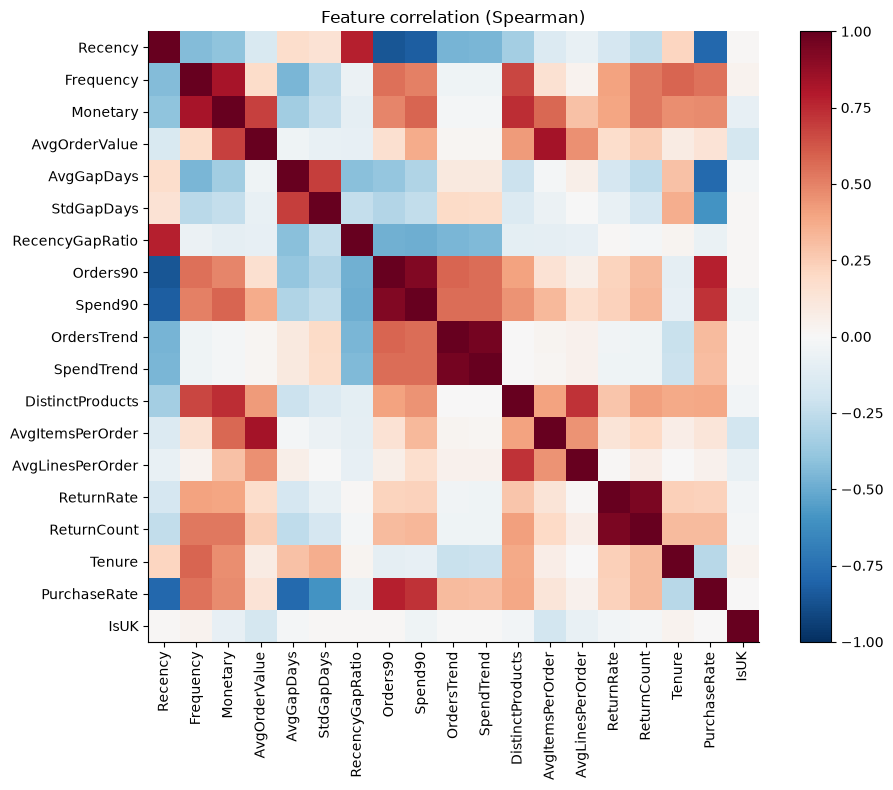

Feature pairs with |correlation| > 0.85 (consider dropping one of each for logistic regression):


,,spearman
OrdersTrend,SpendTrend,0.95
ReturnRate,ReturnCount,0.94
Orders90,Spend90,0.93
Recency,Orders90,-0.85


Correlation of each feature with Churn (a quick sanity check, not a model):


,spearman_with_churn
Frequency,-0.39
Monetary,-0.38
Spend90,-0.34
Orders90,-0.34
PurchaseRate,-0.34
DistinctProducts,-0.32
ReturnCount,-0.24
ReturnRate,-0.18
AvgOrderValue,-0.17
AvgItemsPerOrder,-0.15


In [8]:
num = churn[FEATURES].select_dtypes("number")
corr = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=90)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
ax.set_title("Feature correlation (Spearman)"); plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.savefig(f"{FIG}/15_feature_correlation.png", dpi=120); plt.show()

pairs_hi = (corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
                .loc[lambda s: s.abs() > 0.85].sort_values(key=abs, ascending=False))
print("Feature pairs with |correlation| > 0.85 (consider dropping one of each for logistic regression):")
display(pairs_hi.to_frame("spearman"))

print("Correlation of each feature with Churn (a quick sanity check, not a model):")
display(num.corrwith(churn["Churn"], method="spearman").sort_values().to_frame("spearman_with_churn"))

## 7. How sensitive is the churn rate to the window length?
This table supports the 150-day choice in your report. Blank cells mean the window would run past the end of the data.

In [9]:
def churn_rate(cutoff, days):
    cutoff = pd.Timestamp(cutoff)
    if cutoff + pd.Timedelta(days=days) > DATA_END.normalize() + pd.Timedelta(days=1):
        return np.nan
    last_seen = sales[sales["InvoiceDate"] < cutoff].groupby("CustomerID")["InvoiceDate"].max()
    act = last_seen[last_seen >= cutoff - pd.Timedelta(days=ACTIVE_DAYS)].index
    back = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < cutoff + pd.Timedelta(days=days))]["CustomerID"].unique()
    return 1 - np.isin(act, back).mean()

sens = pd.DataFrame({f"{d} days": {c.strftime("%Y-%m-%d"): churn_rate(c, d) for c in TRAIN_CUTOFFS + [TEST_CUTOFF]}
                     for d in (90, 120, 150, 180)})
sens.apply(lambda col: col.map(lambda v: "-" if pd.isna(v) else f"{v:.1%}"))

,90 days,120 days,150 days,180 days
2010-06-30,51.4%,39.9%,32.4%,30.2%
2010-08-31,41.8%,38.3%,36.8%,35.3%
2010-10-31,55.1%,51.3%,47.7%,44.1%
2010-12-31,67.3%,60.9%,56.2%,52.4%
2011-07-01,61.4%,53.0%,45.7%,-


## 8. Save the dataset and the feature dictionary

In [10]:
out = churn.copy()
out["SnapshotDate"] = out["SnapshotDate"].dt.strftime("%Y-%m-%d")
out["WindowEnd"] = out["WindowEnd"].dt.strftime("%Y-%m-%d")
out.to_csv(f"{DATA}/churn_dataset.csv", index=False)

dictionary = pd.DataFrame([
    ("CustomerID", "id", "Customer identifier"),
    ("SnapshotDate", "id", "Cut-off date: features use data before it, the label uses the 150 days after it"),
    ("WindowEnd", "id", "End of the outcome window"),
    ("Split", "id", "train or test (time-based split)"),
    ("Recency", "feature", "Days since last purchase"),
    ("Frequency", "feature", "Number of orders before the cut-off"),
    ("Monetary", "feature", "Total spend before the cut-off"),
    ("AvgOrderValue", "feature", "Average order value"),
    ("AvgGapDays", "feature", "Average days between purchase days (missing if only 1 purchase day)"),
    ("StdGapDays", "feature", "Standard deviation of the gaps (missing if fewer than 3 purchase days)"),
    ("RecencyGapRatio", "feature", "Recency divided by AvgGapDays; above 1 = overdue"),
    ("Orders90", "feature", "Orders in the last 90 days"),
    ("Spend90", "feature", "Spend in the last 90 days"),
    ("OrdersTrend", "feature", "(orders last 90d - orders previous 90d) / their sum, in [-1, 1]"),
    ("SpendTrend", "feature", "Same for spend"),
    ("DistinctProducts", "feature", "Number of different products ever bought"),
    ("AvgItemsPerOrder", "feature", "Average units per order"),
    ("AvgLinesPerOrder", "feature", "Average different products per order"),
    ("ReturnRate", "feature", "Returned value / spend, capped at 1"),
    ("ReturnCount", "feature", "Number of return invoices"),
    ("Tenure", "feature", "Days since first purchase"),
    ("PurchaseRate", "feature", "Orders per 30 days of tenure"),
    ("Country", "feature", "Customer country (one-hot encode in Step 4)"),
    ("IsUK", "feature", "1 if United Kingdom"),
    ("Churn", "TARGET", "1 = no purchase in the 150 days after the cut-off"),
    ("Outcome_FutureOrders", "OUTCOME - never a feature", "Orders in the outcome window (for simulation/evaluation only)"),
    ("Outcome_FutureSpend", "OUTCOME - never a feature", "Spend in the outcome window (for simulation/evaluation only)"),
], columns=["column", "role", "description"])
assert set(dictionary["column"]) == set(churn.columns), "dictionary and dataset columns differ"
dictionary.to_csv(f"{DATA}/feature_dictionary.csv", index=False)

print(f"Saved {DATA}/churn_dataset.csv  ({len(out):,} rows x {out.shape[1]} columns, {os.path.getsize(f'{DATA}/churn_dataset.csv') / 1e6:.1f} MB)")
print(f"Saved {DATA}/feature_dictionary.csv")
tr_c = set(churn.loc[churn["Split"] == "train", "CustomerID"]); te_c = set(churn.loc[churn["Split"] == "test", "CustomerID"])
print(f"{len(te_c & tr_c) / len(te_c):.0%} of test customers also appear in the training snapshots (earlier in time).")
print("-> in Step 4, use GroupKFold by CustomerID inside the training data so the same customer never sits in both folds.")
display(dictionary)

Saved data/churn_dataset.csv  (18,651 rows x 27 columns, 3.8 MB)
Saved data/feature_dictionary.csv
84% of test customers also appear in the training snapshots (earlier in time).
-> in Step 4, use GroupKFold by CustomerID inside the training data so the same customer never sits in both folds.


,column,role,description
0,CustomerID,id,Customer identifier
1,SnapshotDate,id,"Cut-off date: features use data before it, the..."
2,WindowEnd,id,End of the outcome window
3,Split,id,train or test (time-based split)
4,Recency,feature,Days since last purchase
5,Frequency,feature,Number of orders before the cut-off
6,Monetary,feature,Total spend before the cut-off
7,AvgOrderValue,feature,Average order value
8,AvgGapDays,feature,Average days between purchase days (missing if...
9,StdGapDays,feature,Standard deviation of the gaps (missing if few...


## Next step
Step 4 trains and compares the churn models (logistic regression, Random Forest, XGBoost / LightGBM). Rules for that step:

```python
data = pd.read_csv("data/churn_dataset.csv", parse_dates=["SnapshotDate"])
train, test = data[data.Split == "train"], data[data.Split == "test"]
X_cols = [c for c in data.columns if c not in
          ["CustomerID", "SnapshotDate", "WindowEnd", "Split", "Churn", "Outcome_FutureOrders", "Outcome_FutureSpend"]]
```
- Never use the `Outcome_` columns as features.
- Fit imputers, scalers and encoders on the training rows only (inside a scikit-learn `Pipeline`).
- Use the test snapshot once, at the very end.